# Part 2 · Notebook 4: NDVI and radar time series

**The problem.** NDVI, computed from Sentinel-2's red and near-infrared bands, is the standard way to follow
a crop through the season: emergence, growth, flowering, ripening, harvest. But Sentinel-2 is an optical
satellite: when clouds cover a field, it sees the clouds. Every cloudy date is a hole in the NDVI curve, and
in winter or in a wet spring the holes last weeks.

**Why radar.** Sentinel-1 sends its own microwave signal, which passes through clouds, day and night. What
comes back depends on the structure and water content of the crop, which change as it grows. If radar
follows NDVI closely enough, it can fill the holes that clouds leave.

**Why two seasons.** In real use, a gap-filling model is trained on past seasons and applied to the current
one. This notebook builds the time series of every winter wheat and winter rapeseed plot east of Reims for
2023–24 and 2024–25, and checks three things: how large the holes are, how closely radar follows NDVI, and
whether the crop calendar changes from one year to the next. [Notebook 5](05_ndvi_gapfilling.ipynb) then fills
the holes.

**Data.** RPG 2024 and 2025 (declared plots, shrunk by 10 m to drop edge pixels); Sentinel-2 Level-2A (NDVI)
and Sentinel-1 RTC (VV and VH radar backscatter) from Planetary Computer, October to August. Code:
`src/sentinel_agri/parcels.py` and `timeseries.py`.

*The time series are extracted beforehand with `python scripts/extract_part2.py --season 2023-24` and
`--season 2024-25` (about 40 minutes each, cached); this notebook then loads them.*

In [1]:
import logging
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sentinel_agri.config import FIGURES_DIR, SEASONS
from sentinel_agri.gapfill import MIN_CLEAR_SHARE, build_grid, harmonise_orbits
from sentinel_agri.parcels import select_parcels
from sentinel_agri.timeseries import s1_backscatter, s2_ndvi

warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
warnings.filterwarnings("ignore", message=".*no geotransform.*")
logging.getLogger("rasterio").setLevel(logging.ERROR)
sns.set_theme(style="whitegrid", context="notebook")
CROP_COLORS = {"Winter wheat": "#c99a2e", "Winter rapeseed": "#4c9a2a"}
SEASON_STYLE = {"2023-24": "--", "2024-25": "-"}
MONTHS = mdates.DateFormatter("%b")
MONTH_ORDER = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8]

data = {}
for season in SEASONS:
    parcels = select_parcels(season)
    ndvi, s1 = s2_ndvi(parcels, season), s1_backscatter(parcels, season)
    data[season] = {"parcels": parcels, "ndvi": ndvi, "s1": s1, "grid": build_grid(ndvi, s1, parcels, season)}
    print(f"{season}: {len(parcels)} plots, {ndvi['date'].nunique()} Sentinel-2 dates, {s1.groupby(['date', 'orbit']).ngroups} radar passes")


def season_day(dates, season):
    """Days since 1 October of the season, so that two seasons can share one axis."""
    return (pd.to_datetime(dates) - pd.Timestamp(SEASONS[season][0])).days


def month_ticks(ax):
    starts = pd.date_range("2024-10-01", "2025-08-01", freq="MS")
    ax.set_xticks(season_day(starts, "2024-25"), [d.strftime("%b") for d in starts])

2023-24: 1184 plots, 69 Sentinel-2 dates, 103 radar passes
2024-25: 1254 plots, 93 Sentinel-2 dates, 145 radar passes


## 1. The plots

,2023-24,2024-25
crop,,
Winter wheat,911,944
Winter rapeseed,273,310


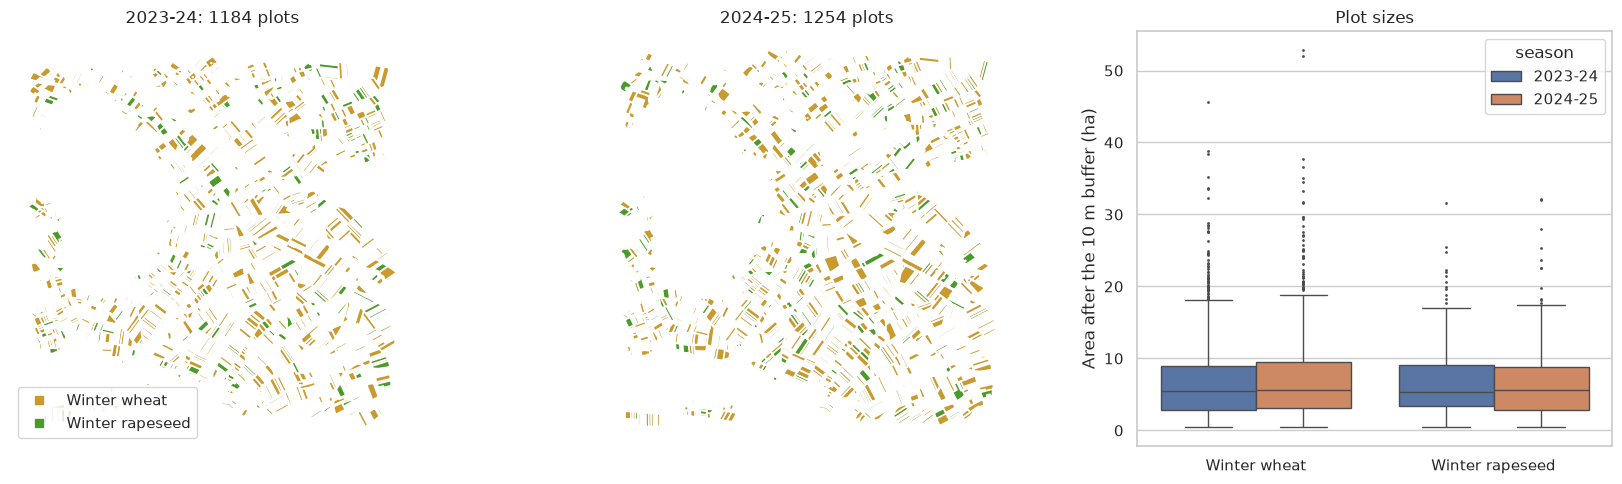

In [2]:
counts = pd.DataFrame({s: d["parcels"]["crop"].value_counts() for s, d in data.items()})
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 0.9]})
for ax, (season, d) in zip(axes[:2], data.items()):
    for crop, color in CROP_COLORS.items():
        d["parcels"][d["parcels"].crop == crop].plot(ax=ax, color=color)
    ax.set_title(f"{season}: {len(d['parcels'])} plots")
    ax.set_axis_off()
axes[0].legend(handles=[plt.Line2D([], [], marker="s", ls="", color=c, label=k) for k, c in CROP_COLORS.items()], loc="lower left")
sizes = pd.concat([d["parcels"][["crop", "area_ha"]].assign(season=s) for s, d in data.items()])
sns.boxplot(data=sizes, x="crop", y="area_ha", hue="season", ax=axes[2], fliersize=1)
axes[2].set_ylabel("Area after the 10 m buffer (ha)")
axes[2].set_xlabel("")
axes[2].set_title("Plot sizes")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_plots.png", dpi=130)
counts

**What it shows**

- 1,184 plots in 2023–24 and 1,254 in 2024–25, three quarters of them wheat.
- Farmers rotate crops, so the plots of the two seasons are mostly different fields. They are in the same
  area and have the same sizes (median about 5.5 ha).

## 2. How clouds cut the NDVI series

An observation counts when at least 90 % of the plot is clear. For each Sentinel-2 date, the share of plots
with a usable observation; then the length of the gaps between usable observations.

median  share_over_15_days  gaps_over_30_days
season  period                                                          
2023-24 March–October         7.0                0.25               2440
        November–February    22.0                0.72               1289
2024-25 March–October         3.0                0.01                  1
        November–February    25.0                0.76               2226

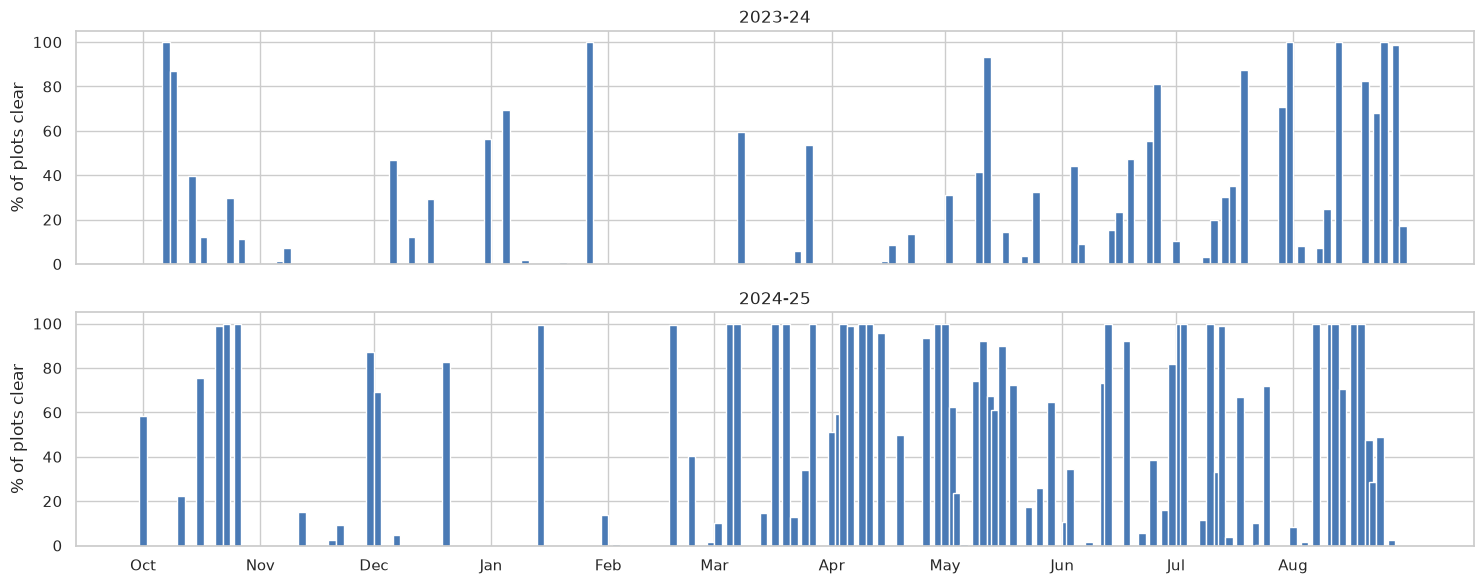

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
gaps = []
for ax, (season, d) in zip(axes, data.items()):
    usable = d["ndvi"][d["ndvi"]["clear_share"] >= MIN_CLEAR_SHARE]
    per_date = usable.groupby("date").size().reindex(sorted(d["ndvi"]["date"].unique()), fill_value=0) / len(d["parcels"]) * 100
    ax.bar(season_day(per_date.index, season), per_date.values, width=2, color="#4a7ab5")
    ax.set_ylabel("% of plots clear")
    ax.set_title(season)
    u = usable.sort_values(["parcel_id", "date"])
    gaps.append(pd.DataFrame({"gap_days": u.groupby("parcel_id")["date"].diff().dt.days, "month": u["date"].dt.month, "season": season}).dropna())
month_ticks(axes[1])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_clear_dates.png", dpi=130)

gaps = pd.concat(gaps, ignore_index=True)
gaps["period"] = np.where(gaps["month"].isin([11, 12, 1, 2]), "November–February", "March–October")
summary = gaps.groupby(["season", "period"])["gap_days"].agg(
    median="median", share_over_15_days=lambda g: (g > 15).mean(), gaps_over_30_days=lambda g: (g > 30).sum()
)
summary.round(2)

**What it shows**

- 2023–24 was much cloudier: 69 Sentinel-2 dates against 93. From March to October, the median gap was 7 days
  against 3, with 2,440 gaps longer than 30 days against 1.
- 2023–24 has no clear image at all in February, and few in March and April. 2024–25 had a clear spring.
- Winter is cloudy in both years: the median gap is 22 to 25 days, and three gaps in four last more than 15 days.

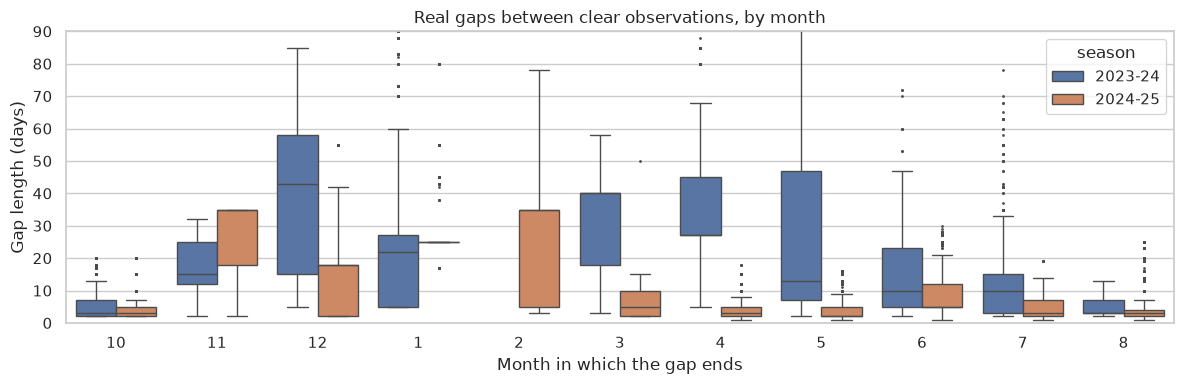

In [4]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=gaps, x="month", y="gap_days", hue="season", order=MONTH_ORDER, fliersize=1)
plt.ylim(0, 90)
plt.xlabel("Month in which the gap ends")
plt.ylabel("Gap length (days)")
plt.title("Real gaps between clear observations, by month")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_real_gaps.png", dpi=130)

**What it shows**

- In 2023–24, spring gaps often lasted 30 to 60 days, just when the crops grow fastest. In 2024–25, spring
  gaps rarely exceed 10 days.
- A model trained on 2023–24 has therefore seen few clear spring values: the two seasons differ in where
  their holes are, not only in how many.

## 3. Does the crop calendar change from one year to the next?

Median NDVI of each crop on the 5-day grid, both seasons on the same axis, with the 25–75 % band (steps with
at least 20 clear plots). Then the day each plot's NDVI first passes 0.5 after January.

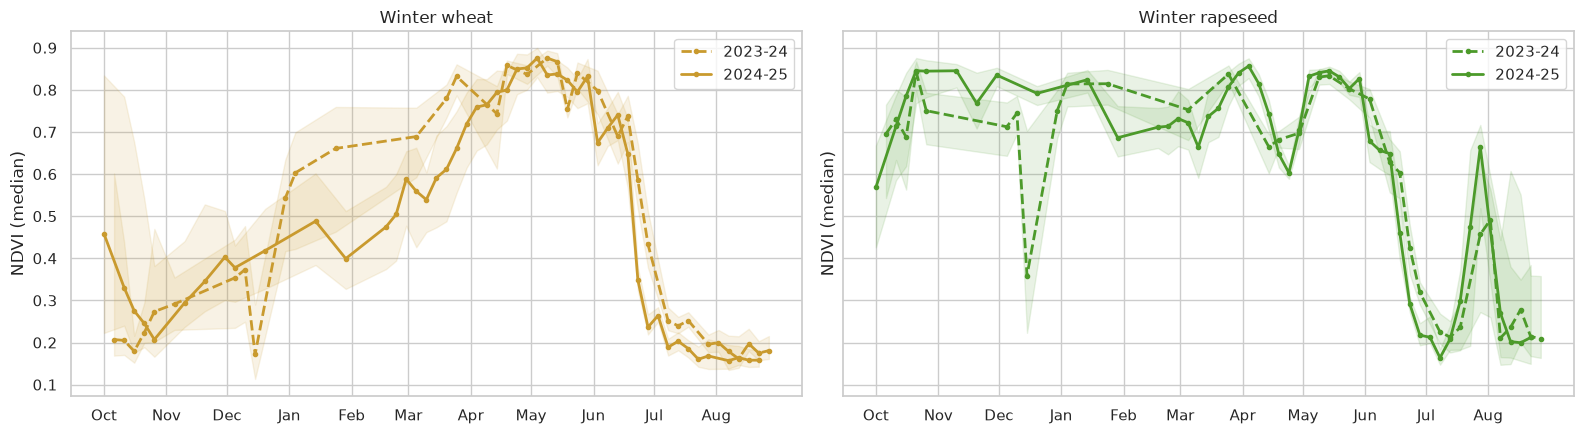

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, (crop, color) in zip(axes, CROP_COLORS.items()):
    for season, d in data.items():
        g = d["grid"]
        ndvi = pd.DataFrame(g.ndvi[g.crops == crop])
        ok = (ndvi.count() >= 20).to_numpy()  # steps with at least 20 clear plots
        q = ndvi.quantile([0.25, 0.5, 0.75]).to_numpy()[:, ok]
        x = season_day(g.dates, season)[ok]
        ax.fill_between(x, q[0], q[2], color=color, alpha=0.12)
        ax.plot(x, q[1], "o" + SEASON_STYLE[season], ms=3, color=color, lw=2, label=season)
    ax.set_title(crop)
    ax.set_ylabel("NDVI (median)")
    month_ticks(ax)
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_ndvi_curves.png", dpi=130)

In [6]:
def crossing_day(g, crop, level=0.5):
    """Median day of the season when NDVI first exceeds `level` after January, per plot."""
    days = []
    for p in np.flatnonzero(g.crops == crop):
        seen = g.observed[p] & (g.dates >= g.dates[0] + pd.Timedelta(days=92))
        above = np.flatnonzero(seen & (g.ndvi[p] > level))
        if len(above):
            days.append((g.dates[above[0]] - g.dates[0]).days)
    return np.median(days)


timing = pd.DataFrame(
    {season: {crop: crossing_day(d["grid"], crop) for crop in CROP_COLORS} for season, d in data.items()}
)
timing.index.name = "median day of the season when NDVI first exceeds 0.5 after January"
timing

,2023-24,2024-25
median day of the season when NDVI first exceeds 0.5 after January,,
Winter wheat,115.0,145.0
Winter rapeseed,95.0,105.0


**What it shows**

- The peak (about 0.87 for wheat in May) and the harvest look alike in both years.
- But wheat greened up about a month earlier in 2023–24, after a mild winter: its NDVI passed 0.5 around day
  115 (late January) against day 145 (late February). In March, the median wheat plot was at 0.77 in
  2023–24 and 0.60 in 2024–25.
- Rapeseed dips in late April, when its yellow flowers cover the leaves, and regrows after the 2025 harvest.
- So the same date does not mean the same stage from one year to the next. A model that leans on the date
  will be off by up to a month.
- The sudden drop on 16 December 2023 (wheat to 0.17, rapeseed to 0.36, back to normal by 31 December) is not
  the crops: it is most likely haze, fog or light snow that the cloud mask missed. The spike filter of notebook
  5 does not remove it, because the next clear date is 15 days later. These 349 values (under 2 % of 2023–24's
  observations) stay in the data, as such errors would in real use.

## 4. Radar through the season

Four orbits see the plots from different angles; `harmonise_orbits` removes each orbit's offset per plot.
Sentinel-1B stopped in December 2021 and Sentinel-1C started in 2025, so 2023–24 has fewer passes.

,2023-24,2024-25
relative orbit,,
37,27,37
59,27,37
110,25,34
161,24,37


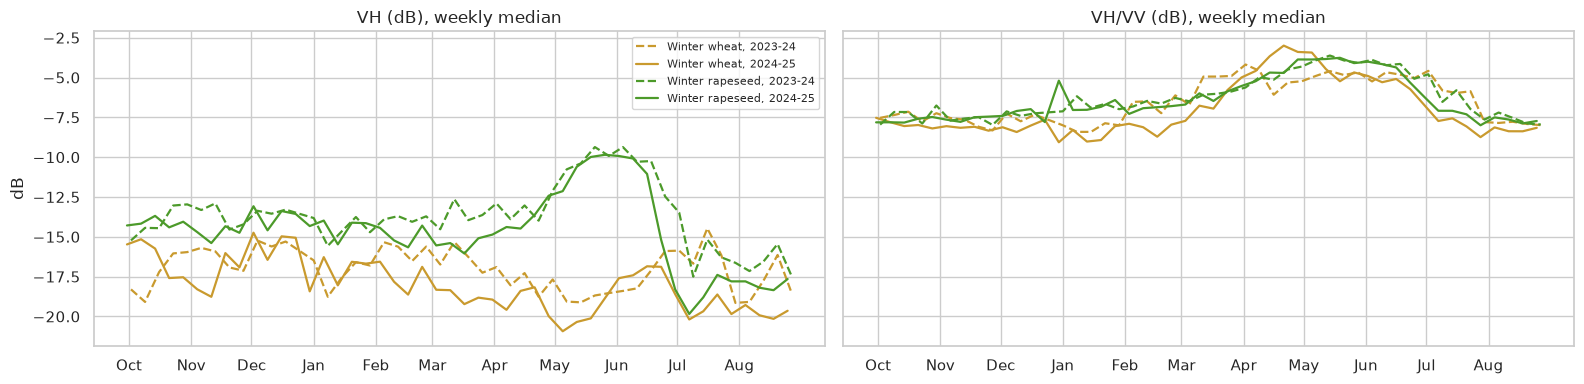

In [7]:
passes = pd.DataFrame({s: d["s1"].groupby("orbit")["date"].nunique() for s, d in data.items()})
passes.index.name = "relative orbit"
fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for ax, (v, name) in zip(axes, [("vh_db", "VH (dB)"), ("ratio_db", "VH/VV (dB)")]):
    for crop, color in CROP_COLORS.items():
        for season, d in data.items():
            s1 = harmonise_orbits(d["s1"])
            s1 = s1[s1["parcel_id"].isin(d["parcels"].loc[d["parcels"].crop == crop, "parcel_id"])]
            weekly = s1.groupby(s1["date"].dt.to_period("W"))[v].median()
            ax.plot(season_day(weekly.index.to_timestamp(), season), weekly.values, SEASON_STYLE[season], color=color, lw=1.6, label=f"{crop}, {season}")
    ax.set_title(f"{name}, weekly median")
    month_ticks(ax)
axes[0].legend(fontsize=8)
axes[0].set_ylabel("dB")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_radar_curves.png", dpi=130)
passes

**What it shows**

- Rapeseed's VH rises from about −15 to −10 dB between April and June as the canopy grows tall and dense,
  then falls by 8 dB at harvest.
- Wheat's VH stays flat; its VH/VV ratio is what follows the crop, rising from −8 to −4 dB in spring.
- In 2023–24, wheat's VH/VV rose about a month earlier, like its NDVI: radar sees the shift in the calendar.
- 2023–24 has about 25 passes per orbit against 35 to 37, because Sentinel-1C only started in 2025.

## 5. Does radar follow NDVI?

Correlation between each usable NDVI value and the radar of the same 5-day step, per crop and season, then
month by month.

VH  VH/VV
crop            season              
Winter rapeseed 2023-24  0.60   0.38
                2024-25  0.68   0.39
Winter wheat    2023-24 -0.12   0.48
                2024-25 -0.01   0.76

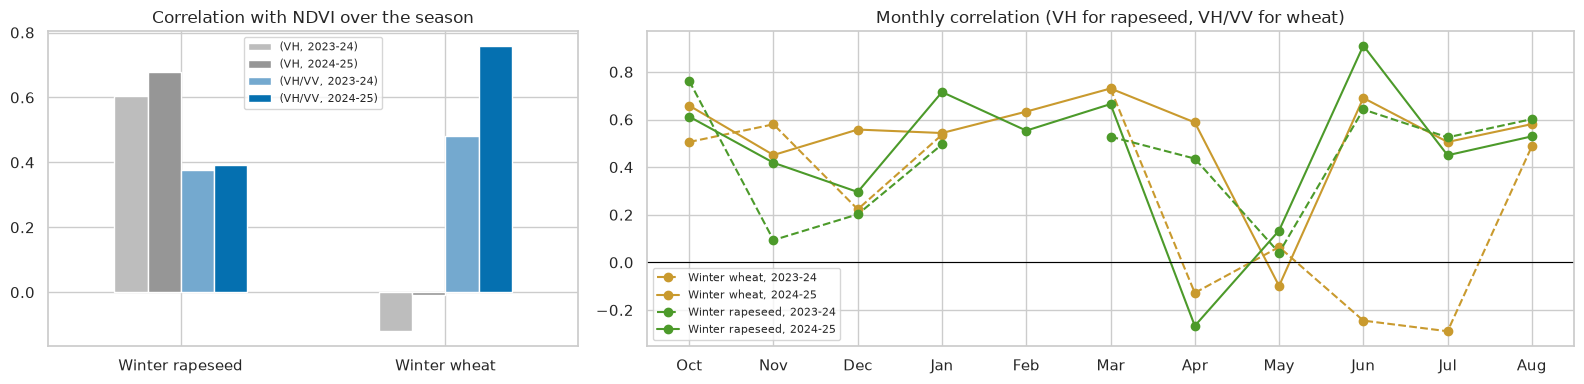

In [8]:
pairs = []
for season, d in data.items():
    g = d["grid"]
    for p in range(len(g.parcel_ids)):
        t = np.flatnonzero(g.observed[p])
        pairs.append(pd.DataFrame({"season": season, "crop": g.crops[p], "month": g.dates[t].month,
                                   "ndvi": g.ndvi[p, t], "VH": g.s1[p, t, 1], "VH/VV": g.s1[p, t, 2]}))
pairs = pd.concat(pairs, ignore_index=True)
overall = pairs.groupby(["crop", "season"]).apply(lambda d: pd.Series({v: d["ndvi"].corr(d[v]) for v in ["VH", "VH/VV"]}), include_groups=False)
monthly = pairs.groupby(["crop", "season", "month"]).apply(lambda d: d["ndvi"].corr(d["VH"] if d.name[0] == "Winter rapeseed" else d["VH/VV"]), include_groups=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [0.8, 1.4]})
overall.unstack("season").plot.bar(ax=axes[0], rot=0, color=["#bdbdbd", "#969696", "#74a9cf", "#0570b0"])
axes[0].set_title("Correlation with NDVI over the season")
axes[0].set_xlabel("")
axes[0].legend(fontsize=8, title=None)
for crop, color in CROP_COLORS.items():
    for season in SEASONS:
        m = monthly.loc[crop, season].reindex(MONTH_ORDER)
        axes[1].plot(range(len(MONTH_ORDER)), m.values, "o" + SEASON_STYLE[season], color=color, label=f"{crop}, {season}")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(range(len(MONTH_ORDER)), [pd.Timestamp(2025, m, 1).strftime("%b") for m in MONTH_ORDER])
axes[1].set_title("Monthly correlation (VH for rapeseed, VH/VV for wheat)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_radar_vs_ndvi.png", dpi=130)
overall.round(2)

**What it shows**

- Over the season, rapeseed's NDVI follows VH (0.60 and 0.68) and wheat's follows VH/VV (0.48 and 0.76).
  Wheat's VH says nothing about its NDVI.
- Month by month, the link breaks in April and May: rapeseed flowers (NDVI drops while the plant is at its
  tallest) and wheat's NDVI saturates near 0.85 while the radar keeps changing. It is strongest in June, at
  ripening and harvest.
- The wheat link is weaker in 2023–24 (0.48), with fewer clear values and fewer radar passes.

## 6. Hypotheses for notebook 5

Notebook 5 first repeats the same-season test on all 2024–25 plots, then tests the real-life case: models
trained on 2023–24, applied to 2024–25. The first two hypotheses come from a pilot run on 300 plots; all six
are written before notebook 5 runs on this data.

| ID | Hypothesis | Refuted if | Guess |
|---|---|---|---|
| G1 | Within one season, learned models halve the error of the straight line, with or without radar. | Gain below 30 % | About −45 % |
| G2 | Within one season, radar adds little when the value after the gap is known. | Radar's effect above 10 % | Under 10 %, mostly rapeseed |
| G3 | Trained on 2023–24, a model without radar does worse on 2024–25 than one trained on 2024–25. | No loss | It loses part of its gain |
| G4 | Across seasons, radar helps more than within one season. | Effect no larger | Clearly larger |
| G5 | In real time across seasons, radar's help grows with the time since the last clear image. | Flat | Largest after 30 days |
| G6 | With real cloud patterns instead of artificial gaps, radar models keep their advantage. | Advantage disappears | Kept |